# Continuum fitting on the real star

Fits the continuum of the A0 star SDSS J172637.24+264127.6 (SDSS
2182-53905-0101) with `continuum.fit_continuum` and checks the result
using the data only.

The method and its settings are explained in the notes. Defaults
(`ContinuumSettings`): `knot_spacing=250` A, `clip_low=2`, `clip_high=4`,
`grow_width=1` A. The checks
against a known synthetic continuum are in `tests/test_continuum.py`
(run `pytest`). Wavelengths in Angstrom (vacuum).

In [17]:
import numpy as np
import matplotlib.pyplot as plt

from spectral_diag.io import query_mast, download_mast_spectra, read_sdss_spec
from spectral_diag.ew import measure_ew
from spectral_diag.continuum import ContinuumSettings, fit_continuum, normalise

obs = query_mast("SDSS J172637.24+264127.6")
paths = download_mast_spectra(obs, download_dir="../data/mast", productSubGroupDescription="SPECTRA")
star = read_sdss_spec(next(p for p in paths if p.name.startswith("spec-lite")))
print(f"{star.wave.size} pixels, {star.wave.min():.0f}-{star.wave.max():.0f} A, median S/N {star.meta['snr']:.0f}")

INFO: Found cached file ../data/mast/spec-lite-2182-53905-0101.fits with expected size 172800. [astroquery.query]
INFO: Found cached file ../data/mast/spec-2182-53905-0101.fits with expected size 748800. [astroquery.query]
3772 pixels, 3812-9207 A, median S/N 62


## 1. The fit

Red points: pixels rejected by the clipping (lines). Blue: the fitted
continuum.

cycling after 9 passes, 71% of pixels kept
continuum only extrapolated below 3917 A


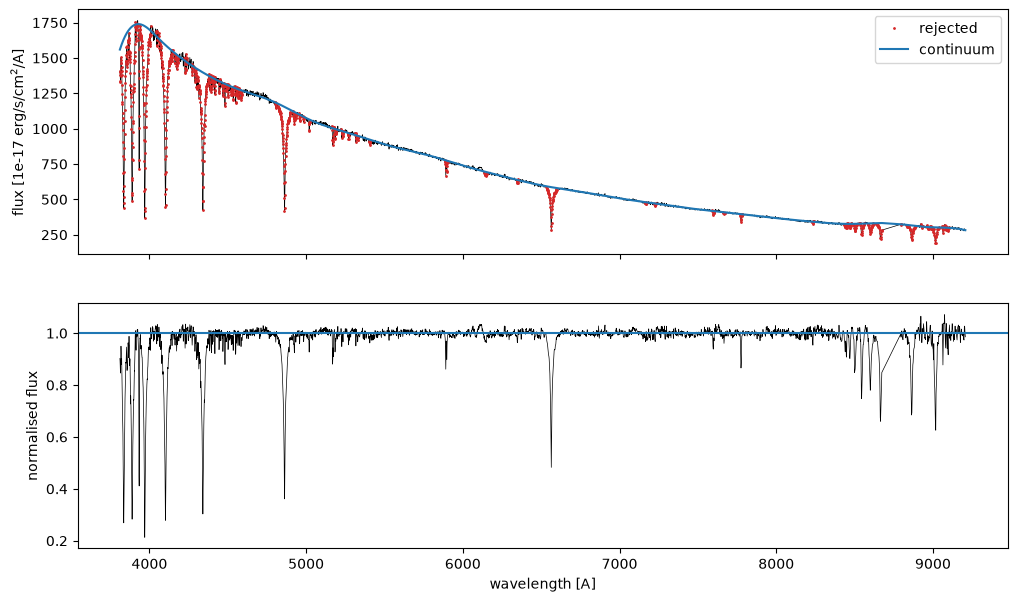

In [18]:
fit = fit_continuum(star)
C, used = fit.continuum, fit.used
norm = normalise(star, C)
defined = np.isfinite(C)

print(f"{fit.status} after {fit.n_iter} passes, {used.mean():.0%} of pixels kept")
print(f"continuum defined (not NaN) over {star.wave[defined].min():.0f}-{star.wave[defined].max():.0f} A")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(star.wave, star.flux, lw=0.5, color="k")
axes[0].plot(star.wave[~used], star.flux[~used], ".", ms=2, color="C3", label="rejected")
axes[0].plot(star.wave, C, color="C0", label="continuum")
axes[0].legend(); axes[0].set_ylabel(r"flux [1e-17 erg/s/cm$^2$/A]")
axes[1].plot(norm.wave, norm.flux, lw=0.5, color="k")
axes[1].axhline(1, color="C0"); axes[1].set_ylabel("normalised flux")
axes[1].set_xlabel("wavelength [A]"); plt.show()

## 2. Zoom on the difficult regions

- Blue end: Balmer lines crowded together, wings overlapping.
- Hbeta and Halpha: the broad lines whose EW depends most on the
  continuum.
- 6800-7700 A: absorption bands of the Earth's atmosphere (O2 near 6870
  and 7600 A). They are rejected like lines, but they do not come from
  the star.

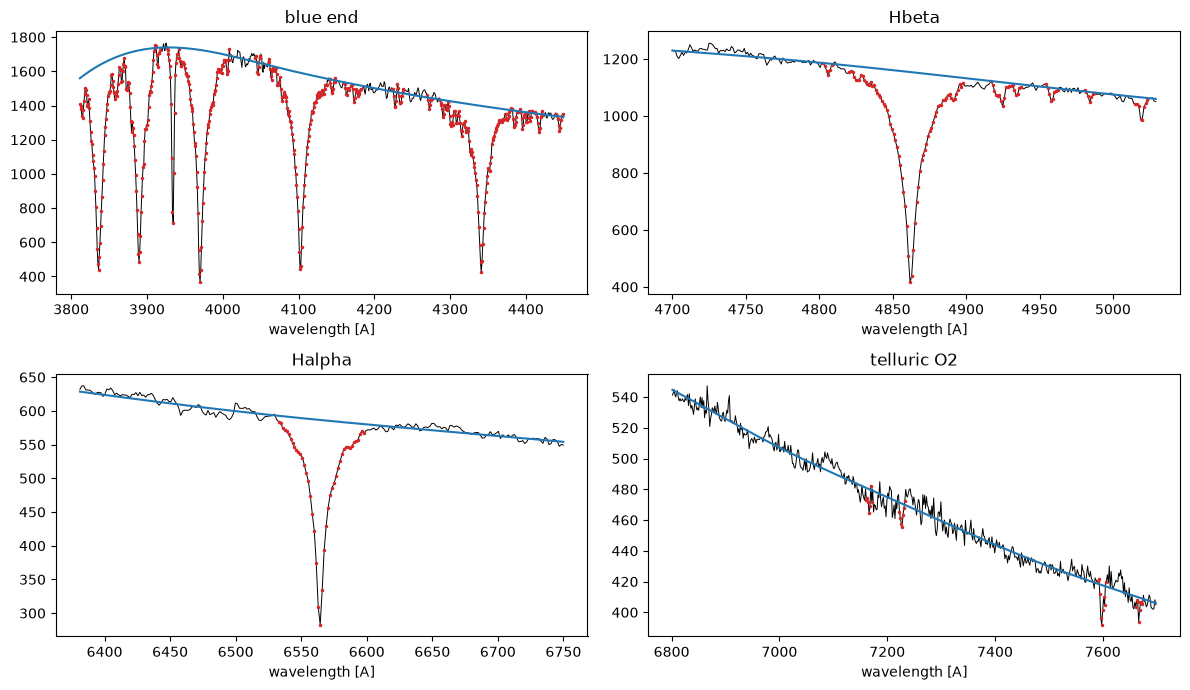

In [19]:
regions = [("blue end", 3800, 4450), ("Hbeta", 4700, 5030), ("Halpha", 6380, 6750), ("telluric O2", 6800, 7700)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (title, lo, hi) in zip(axes.flat, regions):
    sel = (star.wave > lo) & (star.wave < hi)
    ax.plot(star.wave[sel], star.flux[sel], lw=0.7, color="k")
    ax.plot(star.wave[sel & ~used], star.flux[sel & ~used], ".", ms=3, color="C3")
    ax.plot(star.wave[sel], C[sel], color="C0")
    ax.set_title(title); ax.set_xlabel("wavelength [A]")
plt.tight_layout(); plt.show()

## 3. Do the kept pixels look like pure noise?

If the continuum is right, the kept pixels differ from it by noise
only, so `r = (flux - continuum) / error`:
- is centred on 0,
- shows no large-scale pattern: averaged over 200 A bins, `flux /
  continuum - 1` should stay within a few times its own error. A wave
  in these bin averages would mean the spline misses a real bend of the
  continuum (or follows something it should not).

kept pixels: mean r = +0.01, std r = 0.70


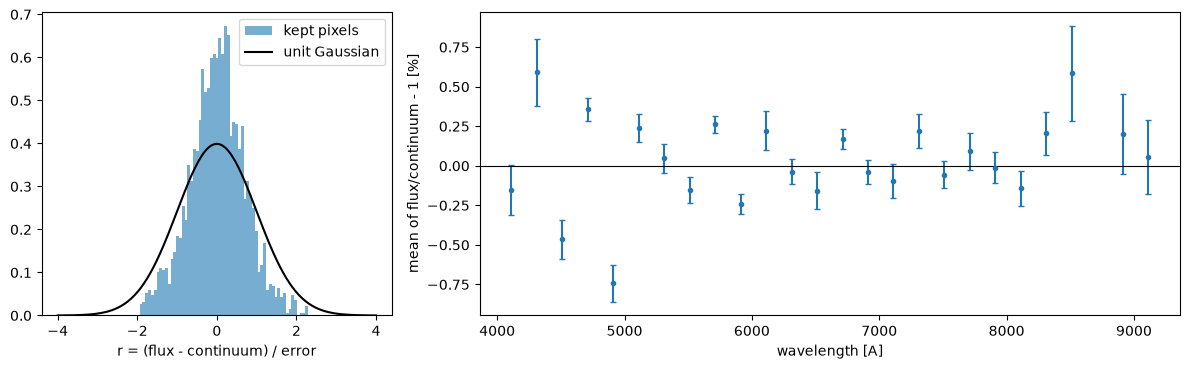

200 A bins more than 3 error bars away from 0:
  4412-4612 A: -0.46% (-3.8 error bars)
  4612-4812 A: +0.36% (+4.7 error bars)
  4812-5012 A: -0.74% (-6.4 error bars)
  5612-5812 A: +0.26% (+4.9 error bars)
  5812-6012 A: -0.24% (-3.8 error bars)
PASS: kept pixels centred on the continuum overall, no bin off by more than 1%.


In [20]:
r = ((star.flux - C) / star.error)[used]
print(f"kept pixels: mean r = {r.mean():+.2f}, std r = {r.std():.2f}")

edges = np.arange(star.wave.min(), star.wave.max() + 200, 200)
centres, mean, err = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    k = used & (star.wave >= lo) & (star.wave < hi)
    if k.sum() < 20:
        continue
    x = star.flux[k] / C[k] - 1
    centres.append(0.5 * (lo + hi)); mean.append(x.mean()); err.append(x.std() / np.sqrt(k.sum()))
centres, mean, err = map(np.array, (centres, mean, err))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].hist(r, bins=60, density=True, color="C0", alpha=0.6, label="kept pixels")
x = np.linspace(-4, 4, 200)
axes[0].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), color="k", label="unit Gaussian")
axes[0].set_xlabel("r = (flux - continuum) / error"); axes[0].legend()
axes[1].errorbar(centres, 100 * mean, 100 * err, fmt="o", ms=3, capsize=2)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set_xlabel("wavelength [A]"); axes[1].set_ylabel("mean of flux/continuum - 1 [%]")
plt.tight_layout(); plt.show()

print("200 A bins more than 3 error bars away from 0:")
for c, m, e in zip(centres, mean, err):
    if abs(m / e) > 3:
        print(f"  {c - 100:.0f}-{c + 100:.0f} A: {m:+.2%} ({m / e:+.1f} error bars)")
assert abs(r.mean()) < 0.2
assert np.abs(mean).max() < 0.01
print("PASS: kept pixels centred on the continuum overall, no bin off by more than 1%.")

Notes on the result:
- The histogram is narrower than the unit Gaussian (std below 1, also
  because the tails are clipped). The pixel errors of the SDSS
  co-added spectrum look too large; a likely reason is that resampling
  onto the final grid correlates neighbouring pixels, which lowers the
  pixel-to-pixel scatter without lowering the errors.
- Overall the kept pixels are centred on the continuum, but a few
  200 A bins are off by several error bars (at most 0.7%). The clearest
  is the bin containing Hbeta: its kept pixels sit on average *below*
  the continuum. Those are the outer wings of Hbeta, too shallow to be
  rejected pixel by pixel, so they stay in the fit; the neighbouring
  bins swing the other way because the spline bends to follow them.
  The bins around 5600-6000 A (NaD and HeI 5876 region) show a smaller
  pattern of the same kind. The synthetic tests show what this does to
  the EW (next section).

## 4. How much do the Balmer EWs depend on the continuum?

Same window (+-100 A) for every line; only the knot spacing changes.
The spread between the rows is the error coming from the continuum.

In [21]:
balmer = {"Ha": 6564.61, "Hb": 4862.68, "Hg": 4341.69, "Hd": 4102.89}  # vacuum, A
centres = {n: w0 * (1 + star.meta["z"]) for n, w0 in balmer.items()}
spacings = [150, 250, 400, 700]

ews = {}
print("spacing " + "".join(f"{n:>8s}" for n in balmer))
for ks in spacings:
    Ck = fit_continuum(star, ContinuumSettings(knot_spacing=ks)).continuum
    ews[ks] = {n: measure_ew(star.wave, star.flux, Ck, star.error, c - 100, c + 100) for n, c in centres.items()}
    print(f"{ks:7d} " + "".join(f"{ews[ks][n][0]:8.2f}" for n in balmer))

default_spacing = int(ContinuumSettings().knot_spacing)
print(f"\nResult with the default continuum ({default_spacing} A): W +- noise +- continuum (std over the spacings)")
for n in balmer:
    W, W_noise = ews[default_spacing][n]
    W_cont = np.std([ews[ks][n][0] for ks in spacings])
    print(f"  {n}: W = {W:5.2f} +- {W_noise:.2f} +- {W_cont:.2f} A")

spacing       Ha      Hb      Hg      Hd
    150     8.96   11.68   16.71   14.27
    250     9.15   14.02   15.39   15.09
    400     9.66   13.20   14.90   15.57
    700     9.43   12.94   16.64   14.83

Result with the default continuum (250 A): W +- noise +- continuum (std over the spacings)
  Ha: W =  9.15 +- 0.26 +- 0.27 A
  Hb: W = 14.02 +- 0.23 +- 0.84 A
  Hg: W = 15.39 +- 0.22 +- 0.78 A
  Hd: W = 15.09 +- 0.22 +- 0.47 A


For these broad lines the continuum error is several times the noise
error. `measure_ew` does not include it yet.

The synthetic tests (`tests/test_continuum.py`) add one more piece of
information that the data alone cannot give: the direction of the
bias. Broad lines come out too weak, because their shallow outer wings
are not rejected and pull the continuum down (about -0.6 A on a 15 A
line at 250 A knot spacing).